# Notebook 04: PCA and an initial quantum-kernel SVM

We compare exact statevector quantum kernels with dummy, linear, RBF and polynomial baselines on identical observations and bounded PCA inputs. Two and four components are prespecified and both are reported. The quantum part computes a similarity matrix; SVM optimization remains classical.

This is an initial simulator experiment. The 2023–2024 evaluation period has already been examined in this project and is exploratory. Results do not establish quantum advantage, statistical significance, or trading profitability.

In [1]:
from pathlib import Path
import json, hashlib, platform, time
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay)
try:
    from qiskit.circuit.library import zz_feature_map
    from qiskit.quantum_info import Statevector
    from qiskit_machine_learning.kernels import FidelityStatevectorKernel
except ImportError as exc:
    raise ImportError('Select an environment installed from requirements-stage4.txt.') from exc

ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
OUT=ROOT/'results/stage4'
OUT.mkdir(parents=True,exist_ok=True)
CONFIG=dict(tickers=['AAPL','MSFT','JPM','XOM','JNJ'],start='2015-01-01',
    validation_start='2021-01-01',test_start='2023-01-01',end='2025-01-01',
    train_dates=40,validation_dates=16,test_dates=20,dimensions=[2,4],
    C=[0.1,1.0,10.0],seed=42,reps=1,entanglement='linear',angle_range=[-np.pi,np.pi])
features=json.loads((ROOT/'data/processed/feature_columns.json').read_text())
assert len(features)==16 and len(set(features))==16
assert not set(features)&{'target_up','forward_return_1d','Date','Ticker'}
print(CONFIG)

{'tickers': ['AAPL', 'MSFT', 'JPM', 'XOM', 'JNJ'], 'start': '2015-01-01', 'validation_start': '2021-01-01', 'test_start': '2023-01-01', 'end': '2025-01-01', 'train_dates': 40, 'validation_dates': 16, 'test_dates': 20, 'dimensions': [2, 4], 'C': [0.1, 1.0, 10.0], 'seed': 42, 'reps': 1, 'entanglement': 'linear', 'angle_range': [-3.141592653589793, 3.141592653589793]}


## Data and label checks
Load selected stocks in chunks. Recover the actual next price observation's date from the cleaned source before filtering. This permits exact purging even if a ticker has missing sessions. Saved labels must match the source prices.

In [2]:
def selected_csv(path,columns):
    parts=[]
    for chunk in pd.read_csv(path,usecols=columns,parse_dates=['Date'],chunksize=200_000):
        parts.append(chunk.loc[chunk.Ticker.isin(CONFIG['tickers'])])
    return pd.concat(parts,ignore_index=True).sort_values(['Ticker','Date'])

prices=selected_csv(ROOT/'data/processed/SP500_cleaned_eligible_tickers.csv',['Ticker','Date','Close'])
prices['label_end']=prices.groupby('Ticker').Date.shift(-1)
prices['expected_target']=(prices.groupby('Ticker').Close.shift(-1)>prices.Close).astype(int)
data=selected_csv(ROOT/'data/processed/SP500_features.csv',['Ticker','Date']+features+['target_up'])
data=data.merge(prices[['Ticker','Date','label_end','expected_target']],on=['Ticker','Date'],how='left',validate='one_to_one')
assert data.label_end.notna().all()
assert (data.target_up==data.expected_target).all()
assert (data.label_end>data.Date).all()
assert np.isfinite(data[features].to_numpy()).all()
assert not data.duplicated(['Ticker','Date']).any()

def date_sample(frame,count):
    dates=np.sort(frame.Date.unique())
    selected=dates[np.linspace(0,len(dates)-1,min(count,len(dates)),dtype=int)]
    return frame.loc[frame.Date.isin(selected)].sort_values(['Date','Ticker']).reset_index(drop=True)

train=date_sample(data.loc[(data.Date>=CONFIG['start'])&(data.Date<CONFIG['validation_start'])&
    (data.label_end<CONFIG['validation_start'])],CONFIG['train_dates'])
validation=date_sample(data.loc[(data.Date>=CONFIG['validation_start'])&(data.Date<CONFIG['test_start'])&
    (data.label_end<CONFIG['test_start'])],CONFIG['validation_dates'])
test=date_sample(data.loc[(data.Date>=CONFIG['test_start'])&(data.Date<CONFIG['end'])&
    (data.label_end<CONFIG['end'])],CONFIG['test_dates'])
assert train.label_end.max()<validation.Date.min()
assert validation.label_end.max()<test.Date.min()
for frame in [train,validation,test]:
    assert frame.target_up.nunique()==2
    assert set(frame.Ticker)==set(CONFIG['tickers'])
development=pd.concat([train,validation],ignore_index=True).sort_values(['Date','Ticker']).reset_index(drop=True)
assert development.label_end.max()<test.Date.min()
split_table=pd.DataFrame([dict(split=name,rows=len(frame),dates=frame.Date.nunique(),
    start=str(frame.Date.min().date()),end=str(frame.Date.max().date()),up_fraction=frame.target_up.mean())
    for name,frame in [('train',train),('validation',validation),('development_refit',development),('evaluation',test)]])
display(split_table)
for name,frame in [('train',train),('validation',validation),('evaluation',test)]:
    frame[['Ticker','Date','label_end','target_up']].to_csv(OUT/f'{name}_sample.csv',index=False)

,split,rows,dates,start,end,up_fraction
0,train,200,40,2015-01-02,2020-12-30,0.535000
1,validation,80,16,2021-01-04,2022-12-29,0.600000
2,development_refit,280,56,2015-01-02,2022-12-29,0.553571
3,evaluation,100,20,2023-01-03,2024-12-30,0.680000


## Encoding and kernel verification
StandardScaler → PCA → MinMaxScaler maps each component into [-π, π]. The mapping learns only from training observations; later values outside training ranges are clipped. We report clipping fractions because it can remove information.

The quantum kernel is squared state overlap: K(x,z) = |⟨φ(x)|φ(z)⟩|². A shallow ZZ feature map with linear entanglement is used. `shots=None` means exact statevector similarities, with no sampling or hardware noise. Kernel eigenvalues, diagonals, symmetry, ranges and independent overlap calculations are checked.

In [3]:
def preprocessing(d):
    return Pipeline([('standard',StandardScaler()),('pca',PCA(n_components=d,svd_solver='full')),
        ('angles',MinMaxScaler(feature_range=tuple(CONFIG['angle_range']),clip=True))])

def clip_fraction(pre,X):
    reduced=pre.named_steps['pca'].transform(pre.named_steps['standard'].transform(X))
    bounds=pre.named_steps['angles']
    return float(((reduced<bounds.data_min_)|(reduced>bounds.data_max_)).mean())

def make_map(d):
    return zz_feature_map(feature_dimension=d,reps=CONFIG['reps'],entanglement=CONFIG['entanglement'])

def kernel_pair(A,B,d,phase):
    circuit=make_map(d)
    kernel=FidelityStatevectorKernel(feature_map=circuit,shots=None)
    started=time.perf_counter(); K=kernel.evaluate(A); train_seconds=time.perf_counter()-started
    started=time.perf_counter(); cross=kernel.evaluate(B,A); cross_seconds=time.perf_counter()-started
    assert K.shape==(len(A),len(A)) and cross.shape==(len(B),len(A))
    assert np.isfinite(K).all() and np.isfinite(cross).all()
    assert np.allclose(K,K.T,atol=1e-9)
    assert np.allclose(np.diag(K),1,atol=1e-9)
    assert min(K.min(),cross.min())>=-1e-9 and max(K.max(),cross.max())<=1+1e-9
    smallest=float(np.linalg.eigvalsh(K).min())
    assert smallest>=-1e-8
    for i,j in [(0,0),(min(2,len(B)-1),min(3,len(A)-1))]:
        state_b=Statevector.from_instruction(circuit.assign_parameters(B[i]))
        state_a=Statevector.from_instruction(circuit.assign_parameters(A[j]))
        independent=float(abs(np.vdot(state_b.data,state_a.data))**2)
        assert np.isclose(cross[i,j],independent,atol=1e-9)
    diagnostic=dict(dimension=d,phase=phase,train_shape=list(K.shape),cross_shape=list(cross.shape),
        min_eigenvalue=smallest,train_kernel_seconds=train_seconds,cross_kernel_seconds=cross_seconds,
        kernel_array_bytes=K.nbytes+cross.nbytes,circuit_depth=circuit.depth(),
        two_qubit_gates=sum(inst.operation.num_qubits==2 for inst in circuit.data),
        operations=dict(circuit.count_ops()))
    return K,cross,diagnostic

def model_for(name,params):
    if name=='dummy': return DummyClassifier(strategy='most_frequent')
    kernel='precomputed' if name=='qsvm' else {'linear':'linear','rbf':'rbf','polynomial':'poly'}[name]
    return SVC(kernel=kernel,class_weight='balanced',**params)

grids={'dummy':[{}], 'linear':list(ParameterGrid({'C':CONFIG['C']})),
       'rbf':list(ParameterGrid({'C':CONFIG['C'],'gamma':['scale',0.01,0.1]})),
       'polynomial':list(ParameterGrid({'C':CONFIG['C'],'degree':[2,3],'gamma':['scale']})),
       'qsvm':list(ParameterGrid({'C':CONFIG['C']}))}

## Select hyperparameters on validation data
For each dimension, all five models use identical rows and the same angle-mapped features. Each SVM searches the same C values; classical kernels also search their listed kernel parameters. This is a common evaluation protocol, not an equal compute budget. Ties select the first configuration in the declared grid.

No evaluation metrics are computed until parameters for both dimensions have been selected and frozen. With a small validation sample, these choices can be unstable.

In [4]:
trials=[]; selected={}; diagnostics=[]; selection_times={}
for d in CONFIG['dimensions']:
    started=time.perf_counter()
    pre=preprocessing(d)
    A=pre.fit_transform(train[features]); V=pre.transform(validation[features])
    assert np.allclose(pre.named_steps['standard'].mean_,train[features].mean().to_numpy())
    assert np.max(np.abs(A))<=np.pi+1e-10 and np.max(np.abs(V))<=np.pi+1e-10
    K,KV,diag=kernel_pair(A,V,d,'selection'); diagnostics.append(diag)
    for name,grid in grids.items():
        best_score=-np.inf; best_params=None
        for params in grid:
            model=model_for(name,params)
            model.fit(K if name=='qsvm' else A,train.target_up)
            pred=model.predict(KV if name=='qsvm' else V)
            score=balanced_accuracy_score(validation.target_up,pred)
            trials.append(dict(dimension=d,model=name,parameters=json.dumps(params),validation_balanced_accuracy=score))
            if score>best_score:
                best_score=score; best_params=params.copy()
        selected[(d,name)]=dict(parameters=best_params,validation_balanced_accuracy=best_score)
    selection_times[d]=time.perf_counter()-started
display(pd.DataFrame([dict(dimension=d,model=name,**value) for (d,name),value in selected.items()]))
frozen_parameters=json.dumps({str(k):v for k,v in selected.items()},sort_keys=True)

,dimension,model,parameters,validation_balanced_accuracy
0,2,dummy,{},0.500000
1,2,linear,{'C': 0.1},0.510417
2,2,rbf,"{'C': 1.0, 'gamma': 0.01}",0.536458
3,2,polynomial,"{'C': 10.0, 'degree': 3, 'gamma': 'scale'}",0.468750
4,2,qsvm,{'C': 10.0},0.505208
5,4,dummy,{},0.500000
6,4,linear,{'C': 0.1},0.510417
7,4,rbf,"{'C': 0.1, 'gamma': 0.01}",0.500000
8,4,polynomial,"{'C': 0.1, 'degree': 3, 'gamma': 'scale'}",0.453125
9,4,qsvm,{'C': 1.0},0.645833


## Refit on development data and evaluate once
After selection, preprocessing is refitted on training plus validation data. Test values only pass through `transform`. The quantum and classical models share these final representations. Both dimensions are reported without selecting a winner from test results.

In [5]:
records=[]; pca_records=[]; preprocess_records={}; predictions=test[['Ticker','Date','target_up']].copy()
final_kernels={}; final_models={}; runtime=[]
for d in CONFIG['dimensions']:
    started=time.perf_counter(); pre=preprocessing(d)
    A=pre.fit_transform(development[features])
    scaler=pre.named_steps['standard']; pca=pre.named_steps['pca']; angles=pre.named_steps['angles']
    before=(scaler.mean_.copy(),pca.components_.copy(),angles.data_min_.copy(),angles.data_max_.copy())
    B=pre.transform(test[features])
    assert all(np.array_equal(x,z) for x,z in zip(before,(scaler.mean_,pca.components_,angles.data_min_,angles.data_max_)))
    assert np.allclose(scaler.mean_,development[features].mean().to_numpy())
    assert np.isfinite(A).all() and np.isfinite(B).all()
    assert np.max(np.abs(B))<=np.pi+1e-10
    prep_seconds=time.perf_counter()-started
    clipping=clip_fraction(pre,test[features])
    preprocess_records[str(d)]=dict(scaler_mean=scaler.mean_.tolist(),scaler_scale=scaler.scale_.tolist(),
        pca_mean=pca.mean_.tolist(),pca_components=pca.components_.tolist(),
        explained_variance_ratio=pca.explained_variance_ratio_.tolist(),
        angle_min=angles.data_min_.tolist(),angle_max=angles.data_max_.tolist(),
        angle_scale=angles.scale_.tolist(),angle_offset=angles.min_.tolist(),test_clipped_fraction=clipping)
    pca_records.append(dict(dimension=d,explained_variance=pca.explained_variance_ratio_.sum(),test_clipped_fraction=clipping))
    K,KT,diag=kernel_pair(A,B,d,'final'); diagnostics.append(diag); final_kernels[d]=K
    for name in grids:
        info=selected[(d,name)]; model=model_for(name,info['parameters'])
        started=time.perf_counter(); model.fit(K if name=='qsvm' else A,development.target_up)
        fit_seconds=time.perf_counter()-started
        started=time.perf_counter(); inputs=KT if name=='qsvm' else B
        pred=model.predict(inputs)
        score=model.decision_function(inputs) if hasattr(model,'decision_function') else model.predict_proba(inputs)[:,1]
        predict_seconds=time.perf_counter()-started
        records.append(dict(dimension=d,model=name,accuracy=accuracy_score(test.target_up,pred),
            balanced_accuracy=balanced_accuracy_score(test.target_up,pred),precision=precision_score(test.target_up,pred,zero_division=0),
            recall=recall_score(test.target_up,pred,zero_division=0),f1=f1_score(test.target_up,pred,zero_division=0),
            roc_auc=roc_auc_score(test.target_up,score),average_precision=average_precision_score(test.target_up,score),
            validation_balanced_accuracy=info['validation_balanced_accuracy'],parameters=json.dumps(info['parameters']),
            fit_seconds=fit_seconds,predict_seconds=predict_seconds,preprocessing_seconds=prep_seconds,
            train_kernel_seconds=diag['train_kernel_seconds'] if name=='qsvm' else 0.0,
            test_kernel_seconds=diag['cross_kernel_seconds'] if name=='qsvm' else 0.0))
        predictions[f'{name}_{d}d_prediction']=pred; predictions[f'{name}_{d}d_score']=score
        final_models[(d,name)]=model
assert json.dumps({str(k):v for k,v in selected.items()},sort_keys=True)==frozen_parameters
metrics=pd.DataFrame(records); pca_summary=pd.DataFrame(pca_records)
assert len(metrics)==10 and np.isfinite(metrics[['accuracy','balanced_accuracy','roc_auc']].to_numpy()).all()
display(metrics[['dimension','model','balanced_accuracy','roc_auc','f1','average_precision']].round(4))
display(pca_summary)
display(pd.DataFrame(diagnostics))
print('Label, temporal, training-only transform, bounded encoding and kernel verification checks passed.')

,dimension,model,balanced_accuracy,roc_auc,f1,average_precision
0,2,dummy,0.5000,0.5000,0.8095,0.6800
1,2,linear,0.5790,0.5979,0.7259,0.7479
2,2,rbf,0.5377,0.5942,0.6167,0.7478
3,2,polynomial,0.5836,0.5786,0.6500,0.7185
4,2,qsvm,0.5165,0.5101,0.7050,0.6727
5,4,dummy,0.5000,0.5000,0.8095,0.6800
6,4,linear,0.5588,0.5538,0.4950,0.7301
7,4,rbf,0.5000,0.5386,0.0000,0.7222
8,4,polynomial,0.4844,0.5528,0.3617,0.7083
9,4,qsvm,0.5414,0.5358,0.5370,0.6819


,dimension,explained_variance,test_clipped_fraction
0,2,0.659586,0.0000
1,4,0.838643,0.0025


,dimension,phase,train_shape,cross_shape,min_eigenvalue,train_kernel_seconds,cross_kernel_seconds,kernel_array_bytes,circuit_depth,two_qubit_gates,operations
0,2,selection,"[200, 200]","[80, 200]",-1.799705e-14,0.244908,0.149416,448000,5,2,"{'p': 3, 'h': 2, 'cx': 2}"
1,4,selection,"[200, 200]","[80, 200]",7.685740e-16,0.288567,0.218817,448000,11,6,"{'p': 7, 'cx': 6, 'h': 4}"
2,2,final,"[280, 280]","[100, 280]",-2.261711e-14,0.428861,0.221939,851200,5,2,"{'p': 3, 'h': 2, 'cx': 2}"
3,4,final,"[280, 280]","[100, 280]",-3.282676e-16,0.505955,0.313004,851200,11,6,"{'p': 7, 'cx': 6, 'h': 4}"


Label, temporal, training-only transform, bounded encoding and kernel verification checks passed.


## Comparison figures
The variance plot measures retained variance in the standardized development features, not predictive information. Kernel heatmaps describe similarities, not probabilities of price increases. Runtime values reflect this machine and exact simulation; kernel array bytes are not peak process memory.

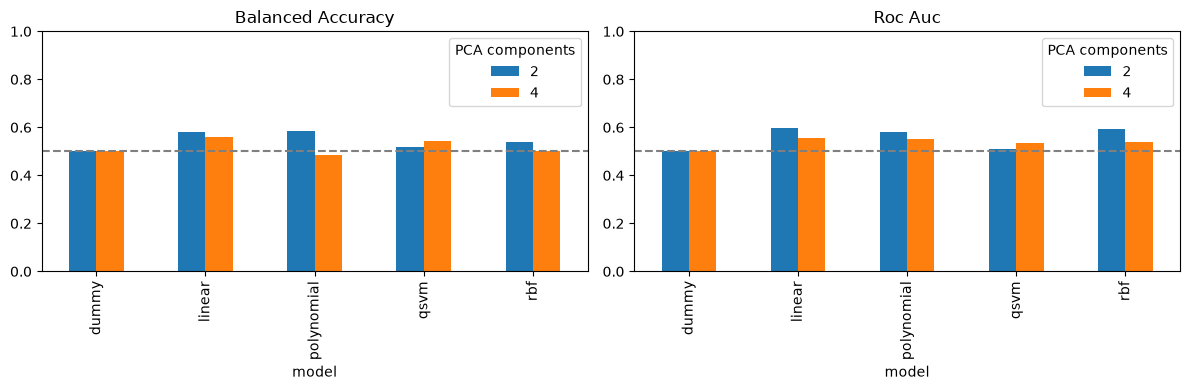

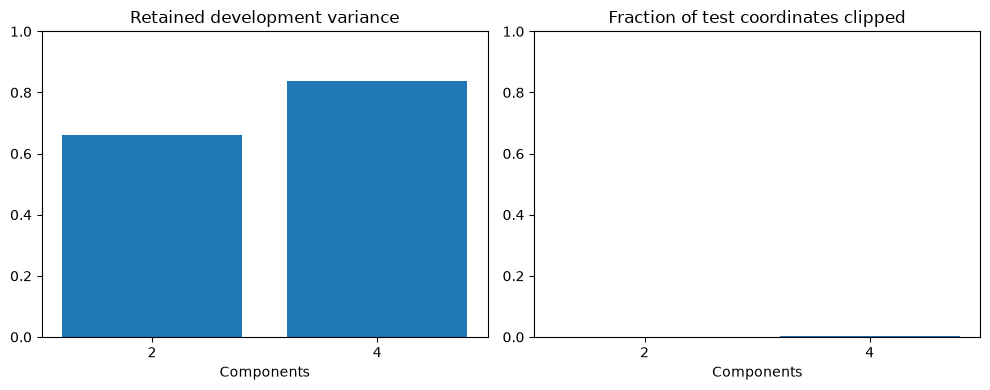

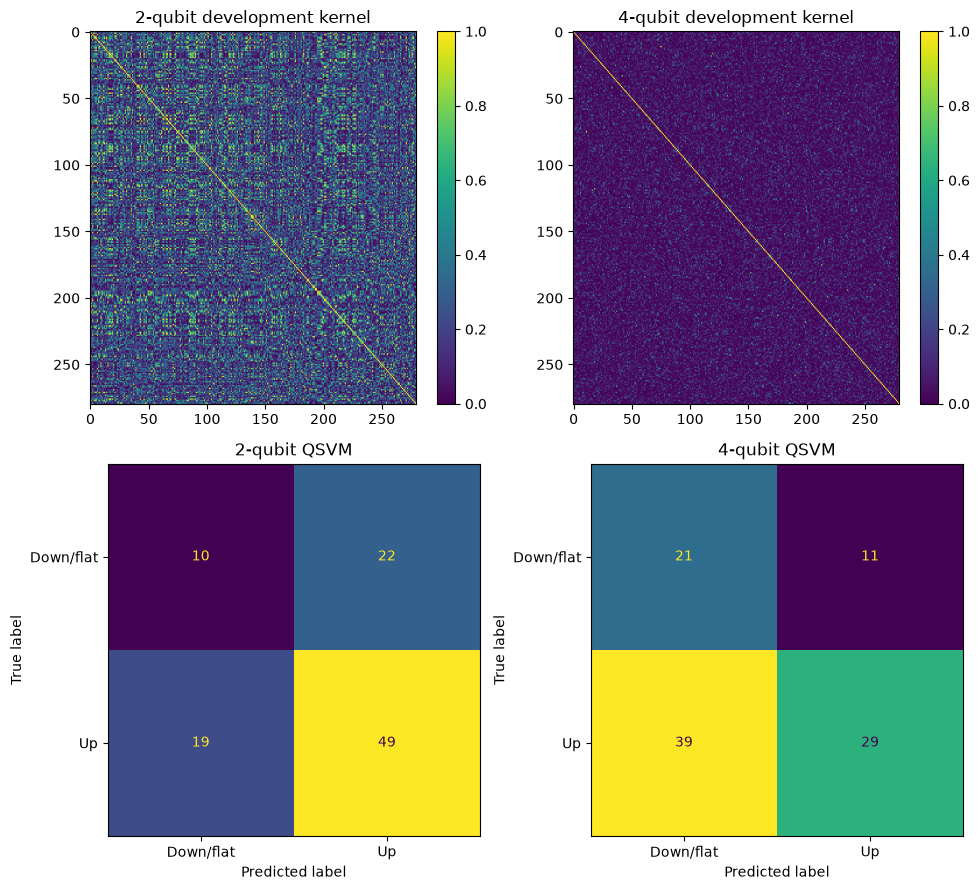

In [6]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,metric in zip(axes,['balanced_accuracy','roc_auc']):
    metrics.pivot(index='model',columns='dimension',values=metric).plot.bar(ax=ax)
    ax.axhline(0.5,color='gray',linestyle='--'); ax.set_ylim(0,1)
    ax.set_title(metric.replace('_',' ').title()); ax.legend(title='PCA components')
fig.tight_layout(); fig.savefig(OUT/'matched_comparison.png',dpi=150); plt.show()
fig,axes=plt.subplots(1,2,figsize=(10,4))
axes[0].bar(pca_summary.dimension.astype(str),pca_summary.explained_variance)
axes[0].set_ylim(0,1); axes[0].set_xlabel('Components'); axes[0].set_title('Retained development variance')
axes[1].bar(pca_summary.dimension.astype(str),pca_summary.test_clipped_fraction)
axes[1].set_ylim(0,1); axes[1].set_xlabel('Components'); axes[1].set_title('Fraction of test coordinates clipped')
fig.tight_layout(); fig.savefig(OUT/'pca_and_clipping.png',dpi=150); plt.show()
fig,axes=plt.subplots(2,2,figsize=(10,9))
for i,d in enumerate(CONFIG['dimensions']):
    display_matrix=axes[0,i].imshow(final_kernels[d],vmin=0,vmax=1,aspect='auto')
    axes[0,i].set_title(f'{d}-qubit development kernel'); fig.colorbar(display_matrix,ax=axes[0,i])
    ConfusionMatrixDisplay(confusion_matrix(test.target_up,predictions[f'qsvm_{d}d_prediction']),
        display_labels=['Down/flat','Up']).plot(ax=axes[1,i],colorbar=False)
    axes[1,i].set_title(f'{d}-qubit QSVM')
fig.tight_layout(); fig.savefig(OUT/'kernels_and_confusions.png',dpi=150); plt.show()

## Save reproducibility evidence
Save exact observation keys, selected parameters, preprocessing parameters, predictions, input hashes and environment versions. Re-running writes the same Stage 4 result paths. Generated results are local; reviewable tables and figures are embedded in this executed notebook.

In [7]:
def sha256(path):
    digest=hashlib.sha256()
    with path.open('rb') as handle:
        for block in iter(lambda:handle.read(1024*1024),b''): digest.update(block)
    return digest.hexdigest()
metrics.to_csv(OUT/'metrics.csv',index=False)
pd.DataFrame(trials).to_csv(OUT/'validation_trials.csv',index=False)
predictions.to_csv(OUT/'predictions.csv',index=False)
split_table.to_csv(OUT/'splits.csv',index=False)
pca_summary.to_csv(OUT/'pca_summary.csv',index=False)
(OUT/'kernel_diagnostics.json').write_text(json.dumps(diagnostics,indent=2),encoding='utf-8')
(OUT/'preprocessing.json').write_text(json.dumps(preprocess_records,indent=2),encoding='utf-8')
metadata=dict(config=CONFIG,features=features,selected_parameters=json.loads(frozen_parameters),
    selection_seconds=selection_times,python=platform.python_version(),
    packages={p:version(p) for p in ['numpy','pandas','scikit-learn','matplotlib','qiskit','qiskit-machine-learning','nbclient','nbformat']},
    input_sha256={p:sha256(ROOT/'data/processed'/p) for p in ['SP500_features.csv','feature_columns.json','SP500_cleaned_eligible_tickers.csv']})
(OUT/'metadata.json').write_text(json.dumps(metadata,indent=2),encoding='utf-8')
print('Stage 4 completed:',OUT)

Stage 4 completed: E:\Quantum Project\results\stage4


## Limits and next steps
This comparison uses small samples from five surviving stocks, 16 engineered inputs reduced to 2 or 4 components, a single fixed feature-map design and exact noiseless simulation. Prices have an unverified adjustment policy. Global historical eligibility and ticker selection can introduce survivorship bias. Observations are correlated by date and ticker, and one small validation interval can yield unstable parameter choices.

The feature dataset's already inspected 2023–2024 period is an exploratory evaluation, not a fresh final holdout. Do not infer significance, profitability, or quantum advantage from these scores. Stage 3 used different sample sizes; compare only matched models within this notebook.

Later stages cover robustness, sample and dimension scaling, circuit/shot/noise variations, and optional hardware validation. Statistical confidence intervals and final report conclusions remain future work.

References: [IBM ZZ feature map](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.zz_feature_map) and [Qiskit FidelityStatevectorKernel](https://qiskit-community.github.io/qiskit-machine-learning/stubs/qiskit_machine_learning.kernels.FidelityStatevectorKernel.html).